In [1]:
import sys
sys.path.append("../python")
from kpi import load_rows
from anomaly_rules import PARAMS, RULES, periods, run_all
import matplotlib.pyplot as plt

In [2]:
rows = load_rows("../datasets/D05_leak.csv")
flags = run_all(rows)
for rule, name in RULES.items():
    print(rule, name, ":", len(periods(rows, flags[rule])), "flagged periods")

ANO_01 Pump running with low flow : 0 flagged periods
ANO_02 Pump running, tank level not rising : 1 flagged periods
ANO_03 High motor current with low flow : 0 flagged periods
ANO_04 Too frequent pump starts : 0 flagged periods
ANO_05 Sensor value out of range or inconsistent : 0 flagged periods
ANO_06 Abnormal difference between pump 1 and pump 2 : 0 flagged periods


In [3]:
for g in periods(rows, flags["ANO_02"]):
    print(f"{g['t_start_min']:.0f} to {g['t_end_min']:.0f} min: {g['message']}")

5133 to 5394 min: pump 1 running for at least 5 min but the tank level changed by -0.17 %/min, expected more than 0.5


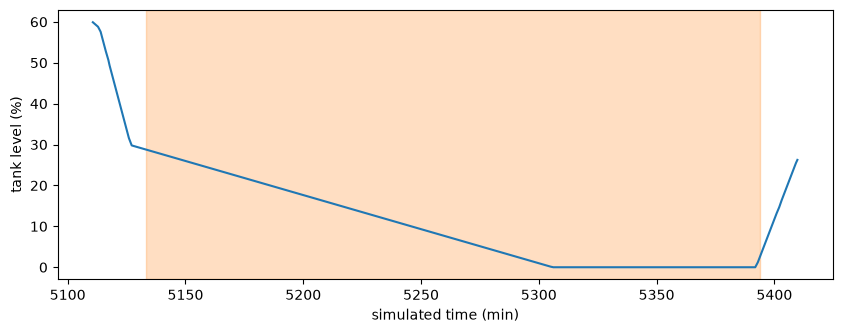

In [4]:
t = [r["SimTime_s"] / 60 for r in rows]
plt.figure(figsize=(10, 3.5))
plt.plot(t, [r["TankLevel_pct"] for r in rows])
for g in periods(rows, flags["ANO_02"]):
    plt.axvspan(g["t_start_min"], g["t_end_min"], alpha=0.25, color="tab:orange")
plt.xlabel("simulated time (min)"); plt.ylabel("tank level (%)"); plt.show()

In [5]:
from anomaly_rules import ano_02
for rate in (0.25, 0.5, 1.0, 1.4):
    p = dict(PARAMS, rise_min_pct_min=rate)
    print(rate, "%/min:", sum(f is not None for f in ano_02(rows, p)), "flagged samples")

0.25 %/min: 257 flagged samples
0.5 %/min: 258 flagged samples
1.0 %/min: 259 flagged samples
1.4 %/min: 260 flagged samples
